## 1. Import Libraries & Configure Environment

We import TensorFlow, Keras layers/models, Scikit-Learn metrics, NumPy, and visualization tools, fixing random seeds for experimental reproducibility.

In [1]:
import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow.keras import layers, models, callbacks, metrics, optimizers
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve

# Set random seeds for reproducibility
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print(f"TensorFlow Version : {tf.__version__}")
print(f"GPU Available      : {bool(tf.config.list_physical_devices('GPU'))}")

TensorFlow Version : 2.21.0
GPU Available      : False


## 2. Dataset Path Configuration & Dynamic Validation Partitioning

As revealed during Stage 1 inspection, the original Kaggle `val/` partition contains only 16 images, which is inadequate for reliable validation monitoring.

We use `tf.keras.utils.image_dataset_from_directory` with `validation_split=0.15` and a fixed random seed (`seed=42`) on the `train` directory:
- **Training Subset ($85\%$)**: $\approx 4,434$ images
- **Validation Subset ($15\%$)**: $\approx 782$ images
- **Test Set**: $624$ images (loaded from `test/` without shuffling for accurate evaluation)

All images are uniformly resized to $224 \times 224$ pixels.

In [2]:
# Relative path to dataset directory
DATASET_PATH = Path("../dataset/chest_xray")
if not DATASET_PATH.exists():
    DATASET_PATH = Path("../Dataset/chest_xray")

TRAIN_DIR = DATASET_PATH / "train"
TEST_DIR = DATASET_PATH / "test"

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

# 1. Load Training Set (85% of train folder)
raw_train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    validation_split=0.15,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary"
)

# 2. Load Validation Set (15% of train folder)
raw_val_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    validation_split=0.15,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary"
)

# 3. Load Test Set (Unshuffled for exact ground-truth alignment)
raw_test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=False
)

CLASS_NAMES = raw_train_ds.class_names
print(f"\nClass Labels Mapping: {dict(enumerate(CLASS_NAMES))}")
print(f"Training Batches   : {len(raw_train_ds)} (Total ~{len(raw_train_ds) * BATCH_SIZE} images)")
print(f"Validation Batches : {len(raw_val_ds)} (Total ~{len(raw_val_ds) * BATCH_SIZE} images)")
print(f"Testing Batches    : {len(raw_test_ds)} (Total ~{len(raw_test_ds) * BATCH_SIZE} images)")

Found 5216 files belonging to 2 classes.
Using 4434 files for training.
Found 5216 files belonging to 2 classes.
Using 782 files for validation.
Found 624 files belonging to 2 classes.

Class Labels Mapping: {0: 'NORMAL', 1: 'PNEUMONIA'}
Training Batches   : 139 (Total ~4448 images)
Validation Batches : 25 (Total ~800 images)
Testing Batches    : 20 (Total ~640 images)


## 3. Class Imbalance Mitigation (Dynamic Class Weights)

In medical diagnostics, failing to detect pneumonia (False Negative) can have severe clinical consequences. Because healthy scans account for only $\approx 26\%$ of the training data, an unweighted cross-entropy loss would naturally favor predicting the majority class (`PNEUMONIA`).

We calculate balanced class weights using `sklearn.utils.class_weight.compute_class_weight` to ensure equal gradient contribution from both classes during backpropagation.

In [3]:
# Extract binary labels from the training dataset batches
print("Extracting training labels for class weight calculation...")
y_train_list = []
for _, y_batch in raw_train_ds:
    y_train_list.extend(y_batch.numpy().flatten())

y_train = np.array(y_train_list)
classes = np.unique(y_train)

# Compute balanced weights
computed_weights = compute_class_weight(class_weight="balanced", classes=classes, y=y_train)
class_weights = {int(cls): float(weight) for cls, weight in zip(classes, computed_weights)}

print("\n--- Computed Class Weights ---")
for cls_idx, weight in class_weights.items():
    count = np.sum(y_train == cls_idx)
    print(f"Class {cls_idx} ({CLASS_NAMES[cls_idx]:<10}): Count = {count:<5} | Weight = {weight:.4f}")

Extracting training labels for class weight calculation...

--- Computed Class Weights ---
Class 0 (NORMAL    ): Count = 1151  | Weight = 1.9262
Class 1 (PNEUMONIA ): Count = 3283  | Weight = 0.6753


## 4. Clinically Sound Data Augmentation & Performance Optimization

### Clinical Constraints on Medical Augmentation:
- **Horizontal Flips**: Allowed — Left/right lung symmetry is standard in anterior-posterior (AP) radiographs.
- **Vertical Flips**: **Strictly Prohibited** — Inverting the thoracic cavity (diaphragm on top, trachea at bottom) violates human anatomy and degrades diagnostic validity.
- **Subtle Rotation & Zoom ($\pm 5\%$)**: Allowed — Simulates slight patient positioning tilt and detector distance variation.

We integrate these augmentations directly into a Keras layer and apply `.cache()` and `.prefetch(buffer_size=tf.data.AUTOTUNE)` to prevent CPU/GPU bottlenecks.

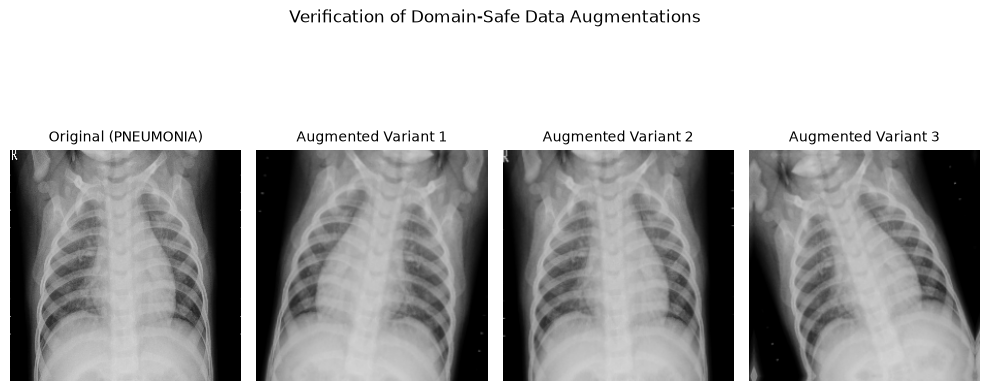

In [4]:
# Define data augmentation layers
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal", seed=SEED),
    layers.RandomRotation(0.05, seed=SEED),
    layers.RandomZoom(0.05, seed=SEED),
], name="data_augmentation")

# Visualizing augmentation on a sample image
for images, labels in raw_train_ds.take(1):
    sample_img = images[0]
    sample_lbl = CLASS_NAMES[int(labels[0].numpy()[0])]
    break

plt.figure(figsize=(10, 5), dpi=100)
plt.subplot(1, 4, 1)
plt.imshow(sample_img.numpy().astype("uint8"), cmap="gray")
plt.title(f"Original ({sample_lbl})", fontsize=10)
plt.axis("off")

for i in range(3):
    augmented = data_augmentation(tf.expand_dims(sample_img, 0), training=True)
    plt.subplot(1, 4, i + 2)
    plt.imshow(augmented[0].numpy().astype("uint8"), cmap="gray")
    plt.title(f"Augmented Variant {i+1}", fontsize=10)
    plt.axis("off")

plt.suptitle("Verification of Domain-Safe Data Augmentations", fontsize=12)
plt.tight_layout()
plt.show()

### Configuring Caching & Prefetching
We chain `cache()` and `prefetch(buffer_size=AUTOTUNE)` to ensure data is read from memory and queued asynchronously ahead of training steps.

In [5]:
AUTOTUNE = tf.data.AUTOTUNE

# Prepare train pipeline with augmentation, caching, shuffling, and prefetching
train_ds = raw_train_ds.map(lambda x, y: (data_augmentation(x, training=True), y), num_parallel_calls=AUTOTUNE)
train_ds = train_ds.cache().shuffle(buffer_size=1000, seed=SEED).prefetch(buffer_size=AUTOTUNE)

# Validation and Test pipelines (no augmentation, only cache + prefetch)
val_ds = raw_val_ds.cache().prefetch(buffer_size=AUTOTUNE)
test_ds = raw_test_ds.cache().prefetch(buffer_size=AUTOTUNE)

print("Input pipelines optimized with caching and prefetching successfully.")

Input pipelines optimized with caching and prefetching successfully.


## 5. Baseline CNN Architecture Design

We design a custom 4-block Convolutional Neural Network:
1. **Input Rescaling Layer**: Scales raw uint8 pixel values $[0, 255] \rightarrow [0, 1.0]$.
2. **Convolutional Blocks 1 to 4**:
   - `Conv2D` layers with kernel size $3 \times 3$, `ReLU` activation, and `same` padding (filters: 32 $\rightarrow$ 64 $\rightarrow$ 128 $\rightarrow$ 128).
   - `BatchNormalization` after each convolution to accelerate convergence and stabilize feature distributions.
   - `MaxPooling2D(2, 2)` to progressively reduce spatial resolution while preserving translational invariance.
3. **Global Average Pooling 2D (`GlobalAveragePooling2D`)**:
   - Collapses spatial dimensions $(B, H, W, C) \rightarrow (B, C)$ without massive flatten weights.
   - Drastically reduces parameter count (prevents overfitting) and establishes a direct feature map channel representation suitable for **Grad-CAM explainability** in subsequent stages.
4. **Classification Head**:
   - `Dense(128, activation='relu')`
   - `Dropout(0.5)` for regularization
   - `Dense(1, activation='sigmoid')` for binary probability output ($P(\text{Pneumonia})$).

In [6]:
def build_baseline_cnn(input_shape=(224, 224, 3)):
    inputs = layers.Input(shape=input_shape, name="input_image")
    
    # Rescale pixel intensities from [0, 255] to [0, 1.0]
    x = layers.Rescaling(1.0 / 255.0, name="rescaling")(inputs)
    
    # Block 1
    x = layers.Conv2D(32, (3, 3), padding="same", activation="relu", name="conv1")(x)
    x = layers.BatchNormalization(name="bn1")(x)
    x = layers.MaxPooling2D((2, 2), name="pool1")(x)
    
    # Block 2
    x = layers.Conv2D(64, (3, 3), padding="same", activation="relu", name="conv2")(x)
    x = layers.BatchNormalization(name="bn2")(x)
    x = layers.MaxPooling2D((2, 2), name="pool2")(x)
    
    # Block 3
    x = layers.Conv2D(128, (3, 3), padding="same", activation="relu", name="conv3")(x)
    x = layers.BatchNormalization(name="bn3")(x)
    x = layers.MaxPooling2D((2, 2), name="pool3")(x)
    
    # Block 4 (Final convolutional feature extractor for Grad-CAM)
    x = layers.Conv2D(128, (3, 3), padding="same", activation="relu", name="conv4_features")(x)
    x = layers.BatchNormalization(name="bn4")(x)
    x = layers.MaxPooling2D((2, 2), name="pool4")(x)
    
    # Global Average Pooling Head
    x = layers.GlobalAveragePooling2D(name="global_avg_pool")(x)
    x = layers.Dense(128, activation="relu", name="dense_fc1")(x)
    x = layers.Dropout(0.5, name="dropout_fc1")(x)
    outputs = layers.Dense(1, activation="sigmoid", name="prediction")(x)
    
    model = models.Model(inputs=inputs, outputs=outputs, name="Baseline_Pneumonia_CNN")
    return model

model = build_baseline_cnn(input_shape=(224, 224, 3))
model.summary()

Model: "Baseline_Pneumonia_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)             │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ rescaling (Rescaling)                │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1 (Conv2D)                       │ (None, 224, 224, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ bn1 (BatchNormalization)             │ (None, 224, 224, 32)        │             128 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ pool1 (MaxPooling2D)                 │ (None, 112, 112, 32)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2 (Conv2D)                       │ (None, 112, 112, 64)        │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ bn2 (BatchNormalization)             │ (None, 112, 112, 64)        │             256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ pool2 (MaxPooling2D)                 │ (None, 56, 56, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv3 (Conv2D)                       │ (None, 56, 56, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ bn3 (BatchNormalization)             │ (None, 56, 56, 128)         │             512 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ pool3 (MaxPooling2D)                 │ (None, 28, 28, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv4_features (Conv2D)              │ (None, 28, 28, 128)         │         147,584 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ bn4 (BatchNormalization)             │ (None, 28, 28, 128)         │             512 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ pool4 (MaxPooling2D)                 │ (None, 14, 14, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_avg_pool                      │ (None, 128)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_fc1 (Dense)                    │ (None, 128)                 │          16,512 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_fc1 (Dropout)                │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ prediction (Dense)                   │ (None, 1)                   │             129 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 258,881 (1011.25 KB)

 Trainable params: 258,177 (1008.50 KB)

 Non-trainable params: 704 (2.75 KB)

## 6. Model Compilation & Training Callbacks

### Clinical Metrics Focus:
- **Binary Cross-Entropy**: Standard loss for binary classification.
- **Recall (Sensitivity)**: **Primary Clinical Metric**. Measures the percentage of actual pneumonia cases detected. In hospital triage, missing a pneumonia patient (False Negative) is significantly more dangerous than a false alarm.
- **Precision (Positive Predictive Value)**: Measures the proportion of predicted pneumonia cases that are genuinely positive.
- **ROC-AUC (Area Under the ROC Curve)**: Measures classification threshold-invariant discriminative power.

### Callbacks:
1. **`ModelCheckpoint`**: Persists the best-performing model weights (`val_loss` minimum) directly into `../models/baseline_cnn_best.keras`.
2. **`EarlyStopping`**: Halts training if `val_loss` stops improving for 5 consecutive epochs, restoring the best weights.
3. **`ReduceLROnPlateau`**: Scales down the learning rate by $5\times$ (`factor=0.2`) when validation loss plateaus for 2 epochs.

In [7]:
# Compile model with Adam optimizer and clinical evaluation metrics
model.compile(
    optimizer=optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        metrics.Precision(name="precision"),
        metrics.Recall(name="recall"),
        metrics.AUC(name="auc")
    ]
)

# Ensure models directory exists
MODELS_DIR = Path("../models")
MODELS_DIR.mkdir(parents=True, exist_ok=True)
MODEL_SAVE_PATH = MODELS_DIR / "baseline_cnn_best.keras"

checkpoint_cb = callbacks.ModelCheckpoint(
    filepath=str(MODEL_SAVE_PATH),
    monitor="val_loss",
    mode="min",
    save_best_only=True,
    verbose=1
)

early_stopping_cb = callbacks.EarlyStopping(
    monitor="val_loss",
    mode="min",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

reduce_lr_cb = callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.2,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

CALLBACKS = [checkpoint_cb, early_stopping_cb, reduce_lr_cb]
print(f"Best model will be saved to: {MODEL_SAVE_PATH.resolve()}")

Best model will be saved to: E:\Pnuemonia Detection\models\baseline_cnn_best.keras


## 7. Model Training

We train the baseline CNN for up to 20 epochs using the dynamic validation set and computed class weights.

> **Execution Note**: Training takes approximately 2–4 minutes per epoch on CPU, or ~20 seconds per epoch on GPU. Early stopping will automatically terminate training once validation loss stabilizes.

In [8]:
EPOCHS = 20

print("Starting baseline CNN training...")
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    class_weight=class_weights,
    callbacks=CALLBACKS,
    verbose=1
)
print("Training complete.")

Starting baseline CNN training...
Epoch 1/20


C:\Users\GOWTHAM\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


139/139 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8615 - auc: 0.9341 - loss: 0.3181 - precision: 0.9664 - recall: 0.8422
Epoch 1: val_loss improved from None to 2.31328, saving model to ..\models\baseline_cnn_best.keras

Epoch 1: finished saving model to ..\models\baseline_cnn_best.keras
139/139 ━━━━━━━━━━━━━━━━━━━━ 159s 1s/step - accuracy: 0.8615 - auc: 0.9341 - loss: 0.3181 - precision: 0.9664 - recall: 0.8422 - val_accuracy: 0.7570 - val_auc: 0.5000 - val_loss: 2.3133 - val_precision: 0.7570 - val_recall: 1.0000 - learning_rate: 0.0010
Epoch 2/20
139/139 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8965 - auc: 0.9616 - loss: 0.2396 - precision: 0.9748 - recall: 0.8830
Epoch 2: val_loss did not improve from 2.31328
139/139 ━━━━━━━━━━━━━━━━━━━━ 153s 1s/step - accuracy: 0.8965 - auc: 0.9616 - loss: 0.2396 - precision: 0.9748 - recall: 0.8830 - val_accuracy: 0.7570 - val_auc: 0.5000 - val_loss: 2.6034 - val_precision: 0.7570 - val_recall: 1.0000 - learning_rate: 0.0010
Epoch 3/20
1

## 8. Learning Curves & Convergence Analysis

We inspect training and validation trajectories across Loss, Accuracy, Recall, and ROC-AUC to verify that the model generalized without catastrophic overfitting.

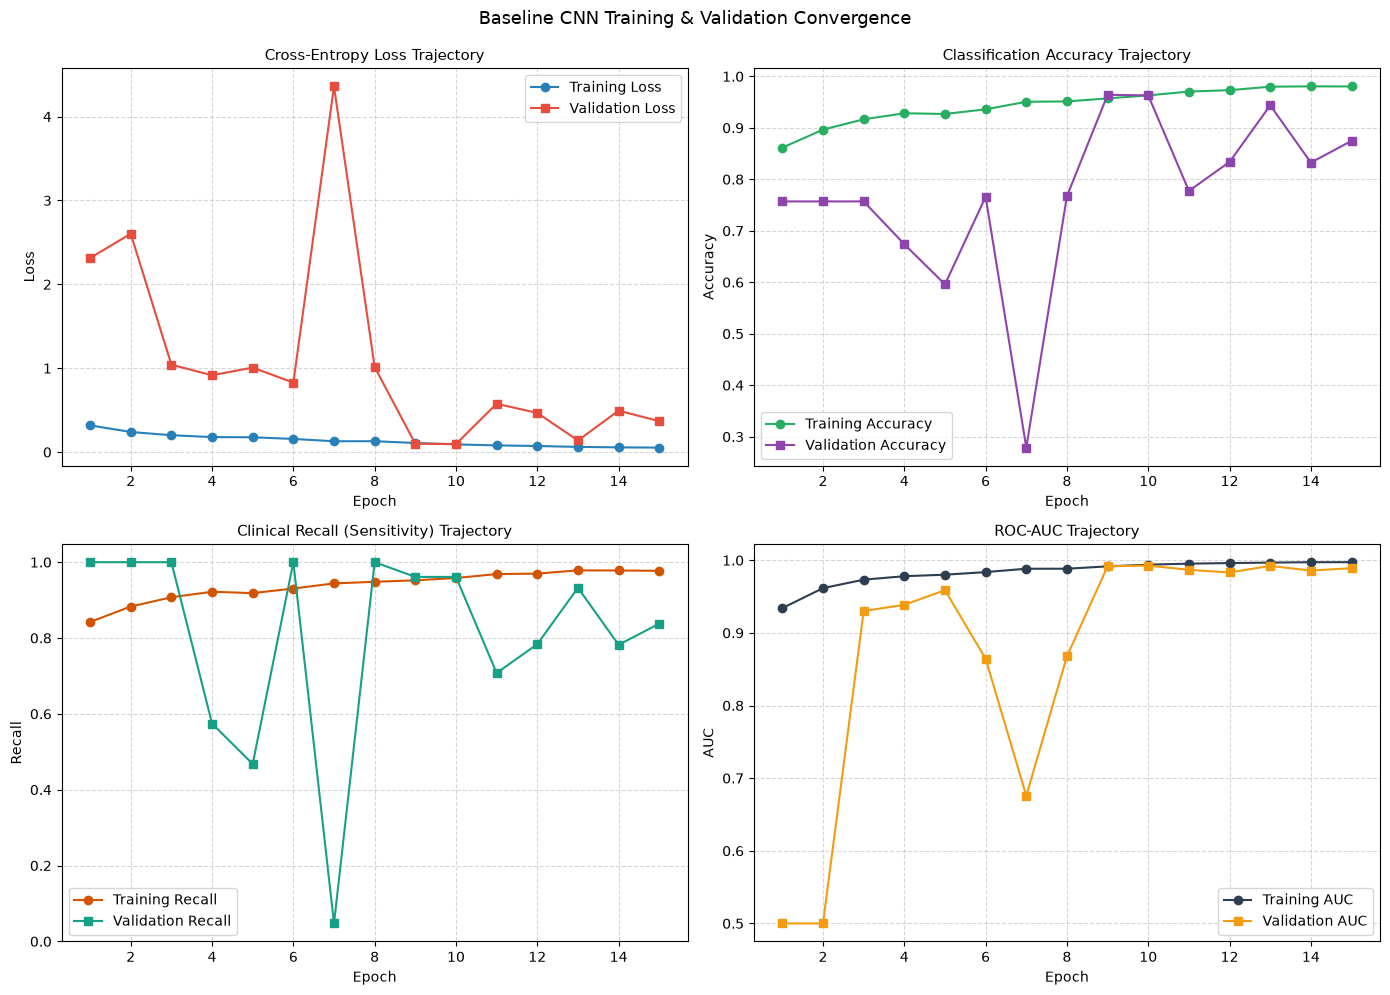

In [9]:
hist_df = pd.DataFrame(history.history)
epochs_range = range(1, len(hist_df) + 1)

fig, axes = plt.subplots(2, 2, figsize=(14, 10), dpi=100)

# 1. Loss
axes[0, 0].plot(epochs_range, hist_df["loss"], label="Training Loss", marker="o", color="#2980b9")
axes[0, 0].plot(epochs_range, hist_df["val_loss"], label="Validation Loss", marker="s", color="#e74c3c")
axes[0, 0].set_title("Cross-Entropy Loss Trajectory", fontsize=11)
axes[0, 0].set_xlabel("Epoch")
axes[0, 0].set_ylabel("Loss")
axes[0, 0].legend()
axes[0, 0].grid(True, linestyle="--", alpha=0.5)

# 2. Accuracy
axes[0, 1].plot(epochs_range, hist_df["accuracy"], label="Training Accuracy", marker="o", color="#27ae60")
axes[0, 1].plot(epochs_range, hist_df["val_accuracy"], label="Validation Accuracy", marker="s", color="#8e44ad")
axes[0, 1].set_title("Classification Accuracy Trajectory", fontsize=11)
axes[0, 1].set_xlabel("Epoch")
axes[0, 1].set_ylabel("Accuracy")
axes[0, 1].legend()
axes[0, 1].grid(True, linestyle="--", alpha=0.5)

# 3. Recall
axes[1, 0].plot(epochs_range, hist_df["recall"], label="Training Recall", marker="o", color="#d35400")
axes[1, 0].plot(epochs_range, hist_df["val_recall"], label="Validation Recall", marker="s", color="#16a085")
axes[1, 0].set_title("Clinical Recall (Sensitivity) Trajectory", fontsize=11)
axes[1, 0].set_xlabel("Epoch")
axes[1, 0].set_ylabel("Recall")
axes[1, 0].legend()
axes[1, 0].grid(True, linestyle="--", alpha=0.5)

# 4. ROC-AUC
axes[1, 1].plot(epochs_range, hist_df["auc"], label="Training AUC", marker="o", color="#2c3e50")
axes[1, 1].plot(epochs_range, hist_df["val_auc"], label="Validation AUC", marker="s", color="#f39c12")
axes[1, 1].set_title("ROC-AUC Trajectory", fontsize=11)
axes[1, 1].set_xlabel("Epoch")
axes[1, 1].set_ylabel("AUC")
axes[1, 1].legend()
axes[1, 1].grid(True, linestyle="--", alpha=0.5)

plt.suptitle("Baseline CNN Training & Validation Convergence", fontsize=13, y=0.99)
plt.tight_layout()
plt.show()

## 9. Comprehensive Evaluation on Unseen Test Dataset

We load the best checkpointed model and perform evaluation on the official unseen test split ($624$ images: $234$ Normal, $390$ Pneumonia).

We compute:
1. **Test Loss, Accuracy, Precision, Recall, AUC**
2. **Confusion Matrix Heatmap** (True Negatives, False Positives, False Negatives, True Positives)
3. **Full Classification Report** (Precision, Recall, F1-Score per class)
4. **ROC Curve Analysis** with calculated AUC score

Loading best model checkpoint from: ..\models\baseline_cnn_best.keras

--- Test Set Evaluation ---
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 179ms/step - accuracy: 0.8317 - auc: 0.9168 - loss: 0.5609 - precision: 0.7963 - recall: 0.9821
Loss         : 0.5609
Compile_metrics : 0.8317
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 163ms/step

--- Detailed Classification Report ---
              precision    recall  f1-score   support

      NORMAL     0.9510    0.5812    0.7215       234
   PNEUMONIA     0.7963    0.9821    0.8794       390

    accuracy                         0.8317       624
   macro avg     0.8737    0.7816    0.8005       624
weighted avg     0.8543    0.8317    0.8202       624



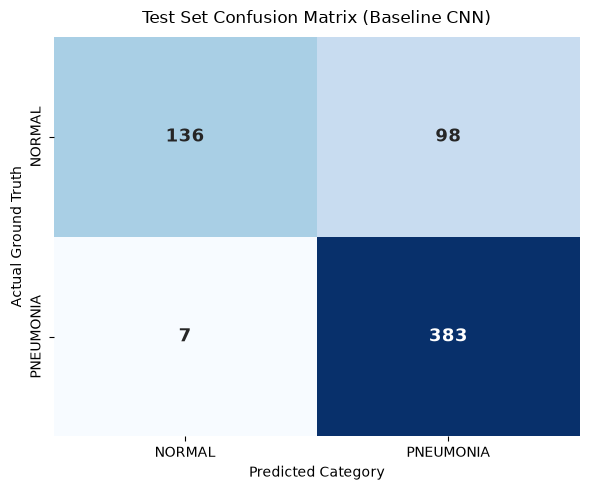

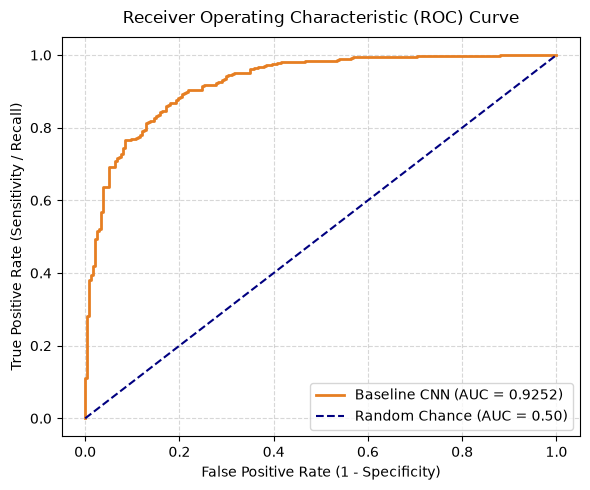

In [10]:
# Load the best saved model checkpoint
print(f"Loading best model checkpoint from: {MODEL_SAVE_PATH}")
best_model = tf.keras.models.load_model(MODEL_SAVE_PATH)

# Evaluate on test set
print("\n--- Test Set Evaluation ---")
test_eval = best_model.evaluate(test_ds, verbose=1)
eval_metrics = dict(zip(best_model.metrics_names, test_eval))
for k, v in eval_metrics.items():
    print(f"{k.capitalize():<12} : {v:.4f}")

# Extract true labels and compute predicted probabilities
y_test_true = []
for _, y_b in raw_test_ds:
    y_test_true.extend(y_b.numpy().flatten())
y_test_true = np.array(y_test_true)

y_pred_probs = best_model.predict(test_ds, verbose=1).flatten()
y_pred_binary = (y_pred_probs >= 0.5).astype(int)

# Classification Report
print("\n--- Detailed Classification Report ---")
print(classification_report(y_test_true, y_pred_binary, target_names=CLASS_NAMES, digits=4))

# Confusion Matrix
cm = confusion_matrix(y_test_true, y_pred_binary)
plt.figure(figsize=(6, 5), dpi=100)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
            cbar=False, annot_kws={"size": 13, "weight": "bold"})
plt.title("Test Set Confusion Matrix (Baseline CNN)", fontsize=12, pad=10)
plt.xlabel("Predicted Category", fontsize=10)
plt.ylabel("Actual Ground Truth", fontsize=10)
plt.tight_layout()
plt.show()

# ROC Curve
fpr, tpr, _ = roc_curve(y_test_true, y_pred_probs)
auc_score = roc_auc_score(y_test_true, y_pred_probs)

plt.figure(figsize=(6, 5), dpi=100)
plt.plot(fpr, tpr, color="#e67e22", lw=2, label=f"Baseline CNN (AUC = {auc_score:.4f})")
plt.plot([0, 1], [0, 1], color="navy", lw=1.5, linestyle="--", label="Random Chance (AUC = 0.50)")
plt.xlabel("False Positive Rate (1 - Specificity)", fontsize=10)
plt.ylabel("True Positive Rate (Sensitivity / Recall)", fontsize=10)
plt.title("Receiver Operating Characteristic (ROC) Curve", fontsize=12, pad=10)
plt.legend(loc="lower right")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()